# Lab 4 - Build the Audience, Then Buy It
Name: Zhmurko Vira | Group: KM-41

## Setup

In [13]:
import importlib.util
import os
import subprocess
import sys
import time
import warnings

started = time.perf_counter()
packages = {"kagglehub":"kagglehub>=0.3,<2", "pandas":"pandas>=2.2,<3",
    "numpy":"numpy>=1.26,<3", "matplotlib":"matplotlib>=3.8,<4", "pyarrow":"pyarrow>=15"}
missing = [v for k,v in packages.items() if importlib.util.find_spec(k) is None]
if missing:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])
warnings.filterwarnings("ignore",message="IProgress not found.*")
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = os.environ.get("LAB4_DATA_DIR")
if DATA is None:
    DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab4-tv-audiences/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")
survey = pd.read_csv(f"{DATA}/purchase_survey.txt",sep="\t",dtype=str,keep_default_na=False)
survey_layout = pd.read_csv(f"{DATA}/purchase_survey_layout.txt",sep="\t",dtype=str,keep_default_na=False)
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")
universe = pd.read_parquet(f"{DATA}/universe.parquet")
plt.rcParams.update({"figure.figsize":(10,4),"figure.dpi":110,
    "axes.spines.top":False,"axes.spines.right":False})
pd.set_option("display.max_columns",14)
pd.set_option("display.max_rows",70)
pd.set_option("display.float_format",lambda x:f"{x:.2f}")
for f in [programs,viewings]:
    for c in ["start_ts","end_ts"]: f[c] = pd.to_datetime(f[c])
programs["broadcast_date"] = pd.to_datetime(programs.broadcast_date)
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights.broadcast_date)
days = pd.date_range("2024-10-01","2024-10-31")
decoded = viewer_attributes.merge(attributes,on="attr_id",how="left",validate="many_to_one")
assert decoded.attr_name.notna().all()
person_ids = pd.Index(decoded.loc[decoded.attr_id.isin([101,102]),"respondent_id"].unique(),name="respondent_id")
demo = pd.DataFrame(index=person_ids)
demo["age"] = decoded.loc[decoded.attr_id.eq(300)].set_index("respondent_id").value
demo["sex"] = decoded.loc[decoded.attr_group.eq("Sex")].set_index("respondent_id").attr_name
assert demo.notna().all().all()
adult_ids = demo.index[demo.age.ge(18)]
person_days = daily_weights.loc[daily_weights.resp_type.isin(["R","L"]) & daily_weights.broadcast_date.isin(days)].copy()
assert not person_days.duplicated(["respondent_id","broadcast_date"]).any()
daily_lookup = person_days.set_index(["respondent_id","broadcast_date"]).weight

Using Colab cache for faster access to the 'adtech-lab4-tv-audiences' dataset.


## Task 1.0 — Clean the survey file

In [14]:
display(survey.head(12))
layout = survey_layout.loc[survey_layout.RECTYPE.eq("B")].copy()
layout["Text"] = layout.Text.str.strip()
codes = layout.set_index("Text").KEYWORD.to_dict()
any_code = codes["Any"]
pair_codes = {codes["1 pair"]:1,codes["2 pairs"]:2,codes["3 or more pairs"]:3}
brand_codes = {name:codes[name] for name in ["STRIDE","KESTREL","EASYWALK"]}
all_brand_codes = layout.loc[layout.Variable.str.contains("BRANDS BOUGHT"),"KEYWORD"]
audit = []
def note(kind,mask,action):
    audit.append({"Problem":kind,"Rows":int(np.asarray(mask).sum()),"Action":action})

s = survey.copy()
header = s.RESPID.str.strip().eq("RESPID")
footer = s.RESPID.str.startswith("TOTAL ROWS:")
note("Repeated header",header,"Drop")
note("Footer",footer,"Drop")
s = s.loc[~header & ~footer].copy()
data_rows = len(s)
for c in s.columns:
    note(f"Whitespace in {c}",s[c].ne(s[c].str.strip()),"Strip whitespace")
    s[c] = s[c].str.strip()
note("Keyword case",s.KEYWORD.ne(s.KEYWORD.str.upper()),"Uppercase")
s["KEYWORD"] = s.KEYWORD.str.upper()
numeric_id = s.RESPID.str.fullmatch(r"[0-9]+(?:\.0+)?")
note("Malformed ID",~numeric_id,"Drop")
note("ID with decimal suffix",s.RESPID.str.contains(r"\.0+$",regex=True),"Remove .0")
note("ID with leading zero",s.RESPID.str.match(r"0[0-9]"),"Parse integer")
s["respondent_id"] = pd.to_numeric(s.RESPID.str.replace(r"\.0+$","",regex=True),errors="coerce").astype("Int64")
note("Unknown code",~s.KEYWORD.isin(layout.KEYWORD),"Drop")
note("Not an adult R/L member",numeric_id & ~s.respondent_id.isin(adult_ids),"Drop")
flag = s.VALUE.str.upper()
yes = flag.isin(["1","1.0","Y","YES","TRUE"])
note("Alternative yes encoding",yes & s.VALUE.ne("1"),"Normalize to yes")
note("No, blank or invalid value",~yes,"Drop: export should contain yes only")
s = s.loc[numeric_id & s.respondent_id.isin(adult_ids) & s.KEYWORD.isin(layout.KEYWORD) & yes].copy()
duplicates = s.duplicated(["respondent_id","KEYWORD"])
note("Duplicate yes answer",duplicates,"Keep one per person/code")
s = s.loc[~duplicates].copy()
pair_rows = s.loc[s.KEYWORD.isin(pair_codes)].copy()
pair_rows["pairs"] = pair_rows.KEYWORD.map(pair_codes)
pair_conflicts = pair_rows.groupby("respondent_id").size().gt(1)
pair_max = pair_rows.groupby("respondent_id").pairs.max()
lower = s.KEYWORD.isin(pair_codes) & s.KEYWORD.map(pair_codes).lt(s.respondent_id.map(pair_max))
note("Lower conflicting pair answer",lower,"Keep higher count")
s = s.loc[~lower].copy()
buyers = pd.Index(s.loc[s.KEYWORD.eq(any_code) | s.KEYWORD.isin(pair_codes) | s.KEYWORD.isin(all_brand_codes),"respondent_id"].unique())
missing_any = buyers.difference(s.loc[s.KEYWORD.eq(any_code),"respondent_id"])
audit.append({"Problem":"Buyer without Any","Rows":len(missing_any),"Action":"Infer Any from a pair count or brand"})
clean_yes = pd.concat([s[["respondent_id","KEYWORD"]],pd.DataFrame({"respondent_id":missing_any,"KEYWORD":any_code})],ignore_index=True)
assert not clean_yes.duplicated(["respondent_id","KEYWORD"]).any()
purchases = pd.DataFrame(index=adult_ids)
purchases["buyer"] = purchases.index.isin(buyers)
purchases["pairs"] = pair_max.reindex(adult_ids,fill_value=0).astype(int)
for brand,keyword in brand_codes.items():
    purchases[brand] = purchases.index.isin(clean_yes.loc[clean_yes.KEYWORD.eq(keyword),"respondent_id"])
assert purchases.index.is_unique
sample_check = layout[["KEYWORD","Text","SAMPLE"]].copy()
sample_check["SAMPLE"] = sample_check.SAMPLE.astype(int)
sample_check["Clean count"] = sample_check.KEYWORD.map(clean_yes.KEYWORD.value_counts()).fillna(0).astype(int)
sample_check["Difference"] = sample_check["Clean count"]-sample_check.SAMPLE
assert sample_check.Difference.eq(0).all()
raw_kestrel = int((survey.KEYWORD.eq(brand_codes["KESTREL"]) & survey.VALUE.eq("1")).sum())
raw_buyer_count = int((survey.KEYWORD.eq(any_code) & survey.VALUE.eq("1")).sum())
raw_buyer_share = raw_buyer_count/len(adult_ids)
clean_buyer_share = purchases.buyer.mean()
print("Survey data rows:",data_rows)
print("Clean yes answers:",len(clean_yes))
print("Adult panel members:",len(adult_ids))
print("Non-buyers:",int((~purchases.buyer).sum()))
print("People with two pair counts:",int(pair_conflicts.sum()))
display(pd.DataFrame(audit))
display(sample_check)
print("Raw Kestrel rows (exact code, VALUE=1):",raw_kestrel)
print("Clean Kestrel members:",int(purchases.KESTREL.sum()))
print("Raw buyer share (row-count baseline):",f"{raw_buyer_share:.3f}")
print("Clean buyer share (unweighted):",f"{clean_buyer_share:.3f}")

,RESPID,KEYWORD,VALUE
0,10415501,X710298,1
1,10072201,x710100,1
2,10302802,X710299,1
3,10070002,X710100,1
4,10130702,X710203,1
5,10243701,X710100,1
6,10342601,X710103,0
7,10399201,X710298,1
8,10364102,X710298,1
9,10200102,X710102,1


Survey data rows: 18346
Clean yes answers: 15635
Adult panel members: 8010
Non-buyers: 3231
People with two pair counts: 113


,Problem,Rows,Action
0,Repeated header,2,Drop
1,Footer,1,Drop
2,Whitespace in RESPID,573,Strip whitespace
3,Whitespace in KEYWORD,370,Strip whitespace
4,Whitespace in VALUE,0,Strip whitespace
5,Keyword case,734,Uppercase
6,Malformed ID,0,Drop
7,ID with decimal suffix,533,Remove .0
8,ID with leading zero,349,Parse integer
9,Unknown code,738,Drop


,KEYWORD,Text,SAMPLE,Clean count,Difference
2,X710100,Any,4779,4779,0
3,X710101,1 pair,1810,1810,0
4,X710102,2 pairs,1308,1308,0
5,X710103,3 or more pairs,1661,1661,0
7,X710201,STRIDE,1563,1563,0
8,X710202,KESTREL,354,354,0
9,X710203,EASYWALK,1050,1050,0
10,X710298,OTHER BRAND,2739,2739,0
11,X710299,DON'T KNOW,371,371,0


Raw Kestrel rows (exact code, VALUE=1): 383
Clean Kestrel members: 354
Raw buyer share (row-count baseline): 0.525
Clean buyer share (unweighted): 0.597


**Answer:** The file mixes repeated headers, a footer, padded or decimal-form IDs, mixed-case codes, alternative yes flags, non-adults, unrelated codes, duplicate answers and conflicting pair counts. I normalized the recoverable fields, removed invalid rows, kept the higher pair count for 113 people and inferred 238 missing Any answers; all nine SAMPLE totals now match. Audit counts describe separate checks and can overlap, so they should not be added as one row-removal total. As a stated raw-file baseline, counting exact uppercase codes with VALUE=1 and trusting one row per person gives 383 Kestrel records instead of 354 buyers, an excess of 29 (8.2%). The same raw Any-row count gives a buyer share of 52.5% rather than 59.7%, or -7.2 percentage points; those are unweighted panel shares, not projected population shares.

## Task 1.1 — Four definitions

In [15]:
audiences = {"P2+":person_ids,"Adults":adult_ids,
    "Buyers":purchases.index[purchases.buyer],"Heavy":purchases.index[purchases.pairs.eq(3)],
    "Kestrel":purchases.index[purchases.KESTREL],"A25-54":demo.index[demo.age.between(25,54)]}
daily_universes = pd.DataFrame({name:person_days.loc[person_days.respondent_id.isin(ids)].groupby("broadcast_date").weight.sum().reindex(days,fill_value=0)
    for name,ids in audiences.items()})
sizes = daily_universes.mean()
print("Adults 18+ (M):",f"{sizes['Adults']/1e6:.1f}")
print("Shoe buyers (M):",f"{sizes['Buyers']/1e6:.1f}")
print("Heavy buyers, 3+ pairs (M):",f"{sizes['Heavy']/1e6:.1f}")
print("Kestrel buyers (M):",f"{sizes['Kestrel']/1e6:.1f}")
print("Adults 25-54 (M):",f"{sizes['A25-54']/1e6:.1f}")
print("Kestrel buyers in panel (n):",len(audiences['Kestrel']))

Adults 18+ (M): 252.6
Shoe buyers (M): 148.1
Heavy buyers, 3+ pairs (M): 49.6
Kestrel buyers (M): 10.0
Adults 25-54 (M): 123.7
Kestrel buyers in panel (n): 354


## Task 1.2 — Who are they?

In [16]:
groups = {}
for prefix,sex in [("M","Male"),("W","Female")]:
    for label,low,high in [("18-34",18,34),("35-54",35,54),("55+",55,np.inf)]:
        groups[f"{prefix}{label}"] = demo.index[demo.sex.eq(sex) & demo.age.between(low,high)]
profiles = []
for name in ["Adults","Buyers","Heavy","Kestrel","A25-54"]:
    for group,ids in groups.items():
        selected_ids = audiences[name].intersection(ids)
        target_size = person_days.loc[person_days.respondent_id.isin(selected_ids)].groupby("broadcast_date").weight.sum().reindex(days,fill_value=0).mean()
        base_size = person_days.loc[person_days.respondent_id.isin(adult_ids.intersection(ids))].groupby("broadcast_date").weight.sum().reindex(days,fill_value=0).mean()
        share = target_size/sizes[name]
        profiles.append({"Audience":name,"Group":group,"Share":share,"Index vs adults":share/(base_size/sizes['Adults'])*100})
profile = pd.DataFrame(profiles)
display(profile.assign(Share=profile.Share.map("{:.3f}".format)))

,Audience,Group,Share,Index vs adults
0,Adults,M18-34,0.144,100.00
1,Adults,M35-54,0.160,100.00
2,Adults,M55+,0.185,100.00
3,Adults,W18-34,0.144,100.00
4,Adults,W35-54,0.160,100.00
5,Adults,W55+,0.208,100.00
6,Buyers,M18-34,0.140,97.43
7,Buyers,M35-54,0.158,99.23
8,Buyers,M55+,0.186,100.77
9,Buyers,W18-34,0.140,97.64


**Answer:** I would give the planner heavy buyers, the definition in the brief: about 49.6 million adults, rather than all 148.1 million buyers or just 10.0 million current Kestrel buyers. Shoe buyers look much like all adults because buying at least one pair is broad, while the heavy definition changes the mix, including more women and ages 35–54. The table uses six age-by-sex cells, so the shares within each audience add to one. The purchase attribute is fused through demographics; it cannot show that watching a particular program causes shoe buying or measure a program-specific buying habit beyond the fusion model.

## Task 2.1 — Programs by audience

In [17]:
def price_telecast(row):
    same = rate_card.loc[rate_card.network_code.eq(row.network_code)]
    program_price = same.loc[same.program_name.eq(row.program_name)]
    if len(program_price):
        assert len(program_price)==1
        return float(program_price.cost_30s_usd.iloc[0])
    shifted = row.start_ts-pd.Timedelta(hours=6)
    minute = shifted.hour*60+shifted.minute+shifted.second/60
    def clock(s):
        h,m = map(int,s.split(":"))
        return h*60+m-360
    candidates = []
    for r in same.loc[same.program_name.isna() | same.program_name.eq("")].itertuples():
        if shifted.dayofweek in r.weekdays and clock(r.start_time)<=minute<clock(r.end_time):
            candidates.append(r.cost_30s_usd)
    assert len(candidates)==1
    return float(candidates[0])

prime = programs.loc[programs.daypart.eq("Prime") & programs.broadcast_date.isin(days)].copy()
sessions = {net:f for net,f in viewings.loc[viewings.resp_type.isin(["R","L"])].groupby("network_code")}
audience_sets = {name:set(ids) for name,ids in audiences.items()}
telecast_rows = []
for row in prime.itertuples():
    f = sessions[row.network_code]
    selected = f.loc[f.start_ts.lt(row.end_ts) & f.end_ts.gt(row.start_ts)].copy()
    minutes = (selected.end_ts.clip(upper=row.end_ts)-selected.start_ts.clip(lower=row.start_ts)).dt.total_seconds()/60
    by_person = minutes.groupby(selected.respondent_id).sum()
    keys = pd.MultiIndex.from_arrays([by_person.index,np.repeat(row.broadcast_date,len(by_person))])
    weights = daily_lookup.reindex(keys).to_numpy()
    assert not np.isnan(weights).any()
    record = {"telecast_id":row.telecast_id,"network_code":row.network_code,"program_name":row.program_name,
        "broadcast_date":row.broadcast_date,"start_ts":row.start_ts,"cost":price_telecast(row)}
    duration = (row.end_ts-row.start_ts).total_seconds()/60
    assert np.isclose(duration,row.duration_min)
    for name in ["P2+","Adults","Heavy","Kestrel"]:
        in_target = by_person.index.isin(audiences[name])
        viewers = np.sum(by_person.to_numpy()[in_target]*weights[in_target])/duration
        record[f"{name} viewers"] = viewers
        record[f"{name} rating"] = viewers/daily_universes.loc[row.broadcast_date,name]*100
        record[f"{name} panelists"] = int(in_target.sum())
    telecast_rows.append(record)
telecast_metrics = pd.DataFrame(telecast_rows)
requested = [("NBC","NFL Football"),("ABC","NFL Football"),("ABC","Dancing with the Stars"),
    ("CBS","NCIS"),("FNC","Hannity"),("HGTV","Unsellable Houses"),
    ("FOOD","Halloween Wars"),("FX","Grotesquerie")]
program_rows = []
for network,title in requested:
    f = telecast_metrics.loc[telecast_metrics.network_code.eq(network) & telecast_metrics.program_name.eq(title)]
    assert len(f)>0
    means = f.select_dtypes(include="number").mean()
    adult_viewers,target_viewers = means["Adults viewers"],means["Heavy viewers"]
    program_rows.append({"Program":f"{title} ({network})","Telecasts":len(f),
        "Adults rating":means["Adults rating"],"Target rating":means["Heavy rating"],
        "Target viewers (000)":target_viewers/1000,"Composition":target_viewers/adult_viewers,
        "Index":means["Heavy rating"]/means["Adults rating"]*100,"Cost per :30":means['cost'],
        "Adults CPM":means['cost']/adult_viewers*1000,"Target CPM":means['cost']/target_viewers*1000,
        "Kestrel index":means["Kestrel rating"]/means["Adults rating"]*100,
        "Mean heavy panelists":means["Heavy panelists"],"Mean Kestrel panelists":means["Kestrel panelists"],
        "Adult viewers":adult_viewers,"Target viewers":target_viewers})
program_table = pd.DataFrame(program_rows).set_index("Program")
columns = ["Adults rating","Target rating","Target viewers (000)","Composition","Index","Cost per :30","Adults CPM","Target CPM"]
display(program_table[columns].assign(**{"Composition":program_table.Composition.map("{:.3f}".format),
    **{c:program_table[c].map("{:.0f}".format) for c in ["Cost per :30","Adults CPM","Target CPM"]}}))
print("Target universe (M):",f"{sizes['Heavy']/1e6:.1f}")

,Adults rating,Target rating,Target viewers (000),Composition,Index,Cost per :30,Adults CPM,Target CPM
Program,,,,,,,,
NFL Football (NBC),5.82,5.79,2865.05,0.195,99.34,487200,33,170
NFL Football (ABC),8.93,8.36,4149.07,0.184,93.58,723600,32,174
Dancing with the Stars (ABC),3.25,3.14,1564.23,0.191,96.78,158600,19,101
NCIS (CBS),2.21,2.43,1206.34,0.216,110.06,178800,32,148
Hannity (FNC),1.09,0.84,416.88,0.152,77.11,39900,15,96
Unsellable Houses (HGTV),0.50,0.64,317.25,0.249,126.77,12900,10,41
Halloween Wars (FOOD),0.28,0.33,161.93,0.228,116.24,9700,14,60
Grotesquerie (FX),0.26,0.25,124.24,0.188,95.91,7592,11,61


Target universe (M): 49.6


## Task 2.2 — Index, volume or price?

Highest index (program): Unsellable Houses (HGTV)
Most target viewers (program): NFL Football (ABC)
Lowest target CPM (program): Unsellable Houses (HGTV)


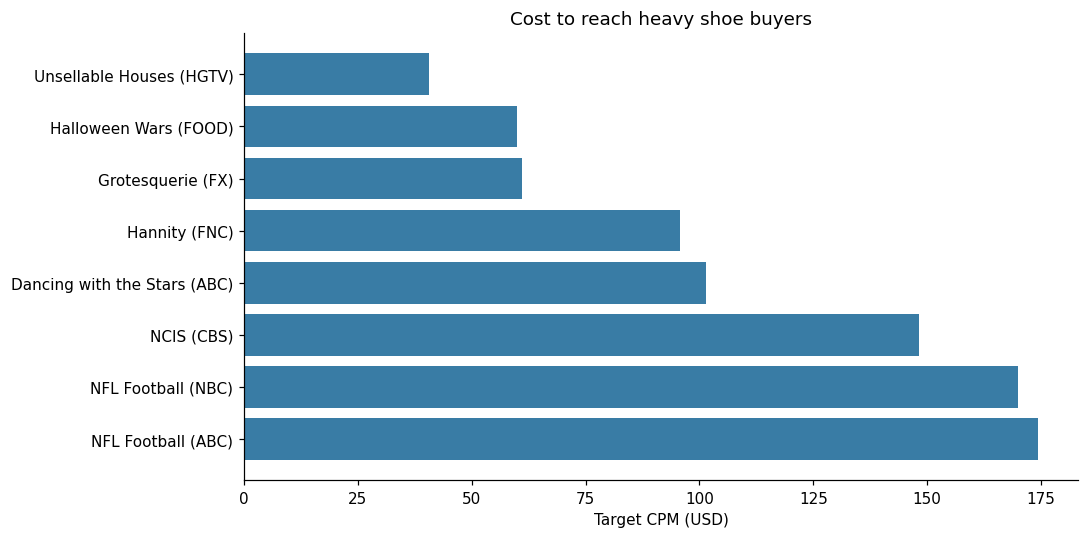

In [18]:
highest_index = program_table.Index.idxmax()
most_viewers = program_table["Target viewers"].idxmax()
cheapest = program_table["Target CPM"].idxmin()
print("Highest index (program):",highest_index)
print("Most target viewers (program):",most_viewers)
print("Lowest target CPM (program):",cheapest)
fig,ax = plt.subplots(figsize=(10,5))
ordered = program_table.sort_values("Target CPM")
ax.barh(ordered.index,ordered["Target CPM"],color="#397ca5")
ax.invert_yaxis()
ax.set(xlabel="Target CPM (USD)",title="Cost to reach heavy shoe buyers")
fig.tight_layout()
plt.show()

**Answer:**

Unsellable Houses (HGTV) has both the highest heavy-buyer index and the lowest target CPM, but NFL Football (ABC) delivers the most target viewers. HGTV's 126.8 index and roughly 317 thousand target viewers per spot answer a different question from ABC football's roughly 4.15 million target viewers. I would buy on target CPM, available volume and the client's goals together: a high index alone says nothing about how much inventory costs or how many buyers it reaches.

## Task 2.3 — Kestrel buyers

In [19]:
display(program_table[["Index","Kestrel index","Mean heavy panelists","Mean Kestrel panelists"]].rename(columns={"Index":"Heavy-buyer index"}))

,Heavy-buyer index,Kestrel index,Mean heavy panelists,Mean Kestrel panelists
Program,,,,
NFL Football (NBC),99.34,98.53,329.00,75.25
NFL Football (ABC),93.58,85.89,292.67,69.33
Dancing with the Stars (ABC),96.78,82.75,122.56,23.44
NCIS (CBS),110.06,56.52,86.33,11.00
Hannity (FNC),77.11,42.65,15.86,2.09
Unsellable Houses (HGTV),126.77,76.91,25.38,4.00
Halloween Wars (FOOD),116.24,95.24,13.67,2.78
Grotesquerie (FX),95.91,129.58,11.36,3.08


**Answer:** Only 354 adult panel members are Kestrel buyers, compared with 1,661 heavy buyers, and far fewer watch any individual airing. Hannity averages about 2.1 Kestrel panelists and Grotesquerie about 3.1, so a handful of people can move the brand index a lot. I would trust the heavy-buyer index more, check the per-airing counts and stability across weeks, and compare with a larger independent purchase sample before making a brand-specific buy.

## Task 3.1 — Weights

In [20]:
acr = acr_sessions.copy()
for old,new in [("start_utc","start_ts"),("end_utc","end_ts")]:
    acr[new] = pd.to_datetime(acr[old],utc=True).dt.tz_convert("America/New_York").dt.tz_localize(None)
for c in ["network_code","session_type","hashed_ip"]: acr[c] = acr[c].astype("category")
acr = acr.loc[(acr.end_ts-acr.start_ts).dt.total_seconds().ge(60),
    ["tv_id","hashed_ip","network_code","session_type","start_ts","end_ts"]].copy()
period = pd.date_range("2024-10-14","2024-10-27")
start,end = period[0]+pd.Timedelta(hours=6),period[-1]+pd.Timedelta(days=1,hours=6)
current = acr.copy()
parts = []
while not current.empty:
    dates = (current.start_ts-pd.Timedelta(hours=6)).dt.normalize()
    stops = pd.concat([current.end_ts,dates+pd.Timedelta(days=1,hours=6)],axis=1).min(axis=1)
    part = current.copy()
    part["end_ts"],part["broadcast_date"] = stops,dates
    parts.append(part.loc[part.broadcast_date.isin(period)])
    current["start_ts"] = stops
    current = current.loc[current.start_ts.lt(current.end_ts)].copy()
acr = pd.concat(parts,ignore_index=True)
tv_ips = acr[["tv_id","hashed_ip"]].drop_duplicates()
assert tv_ips.tv_id.is_unique
counts = hh_attributes.groupby("hashed_ip").household_id.nunique()
unique_hh = hh_attributes.loc[hh_attributes.hashed_ip.map(counts).eq(1)].copy()
matched = tv_ips.merge(unique_hh,on="hashed_ip",how="inner",validate="many_to_one")
matched["head_age"] = np.where(matched.head_age_band.eq("65+"),"65+","Under 65")
tv_days = acr[["tv_id","broadcast_date"]].drop_duplicates().merge(
    matched[["tv_id","head_age","income_band"]],on="tv_id",validate="many_to_one")
cell_keys = ["broadcast_date","head_age","income_band"]
cell_counts = tv_days.groupby(cell_keys,observed=True).tv_id.size().rename("cell_n").reset_index()
assert len(cell_counts)==len(period)*len(universe)
tv_days = tv_days.merge(cell_counts,on=cell_keys,validate="many_to_one").merge(
    universe,on=["head_age","income_band"],validate="many_to_one")
tv_days["weight"] = tv_days.tv_households/tv_days.cell_n
income_targets = universe.groupby("income_band").tv_households.sum()
income_n = tv_days.groupby(["broadcast_date","income_band"]).tv_id.transform("size")
tv_days["income_weight"] = tv_days.income_band.map(income_targets)/income_n
daily_weight_sums = tv_days.groupby("broadcast_date").weight.sum()
assert np.allclose(daily_weight_sums,universe.tv_households.sum())
cell_sums = tv_days.groupby(cell_keys,observed=True).weight.sum().reset_index().merge(universe,on=["head_age","income_band"])
assert np.allclose(cell_sums.weight,cell_sums.tv_households)
tv_weight_lookup = tv_days.set_index(["tv_id","broadcast_date"]).weight
live_acr = acr.loc[acr.session_type.eq("live") & acr.tv_id.isin(matched.tv_id)]
weighted_rows = []
refs = reference_ratings.merge(programs,on="telecast_id",validate="one_to_one")
for row in refs.itertuples():
    f = live_acr.loc[live_acr.network_code.eq(row.network_code) & live_acr.start_ts.lt(row.end_ts) & live_acr.end_ts.gt(row.start_ts)]
    seconds = (f.end_ts.clip(upper=row.end_ts)-f.start_ts.clip(lower=row.start_ts)).dt.total_seconds()
    overlap = seconds.groupby(f.tv_id).sum()
    seen = overlap.index[overlap.ge(60)]
    day = tv_days.loc[tv_days.broadcast_date.eq(row.broadcast_date)].set_index("tv_id")
    assert seen.isin(day.index).all()
    weighted_rows.append({"Program":f"{row.program_name} ({row.network_code})","Unweighted":len(seen)/len(day)*100,
        "Weighted":day.weight.reindex(seen).sum()/day.weight.sum()*100,
        "Income only":day.income_weight.reindex(seen).sum()/day.income_weight.sum()*100,"Reference":row.hh_rating})
weighted_ratings = pd.DataFrame(weighted_rows).set_index("Program")
gap_raw = (weighted_ratings.Unweighted-weighted_ratings.Reference).abs().mean()
gap_weighted = (weighted_ratings.Weighted-weighted_ratings.Reference).abs().mean()
gap_closed = (gap_raw-gap_weighted)/gap_raw
print("TVs matched to one household:",len(matched))
print("Weights sum per day (M):",f"{daily_weight_sums.mean()/1e6:.1f}")
display((daily_weight_sums/1e6).rename("Weight sum (M)").to_frame())
display(weighted_ratings)
print("Mean gap unweighted (points):",f"{gap_raw:.2f}")
print("Mean gap weighted (points):",f"{gap_weighted:.2f}")
print("Share of gap closed:",f"{gap_closed:.3f}")

TVs matched to one household: 19607
Weights sum per day (M): 125.8


,Weight sum (M)
broadcast_date,
2024-10-14,125.80
2024-10-15,125.80
2024-10-16,125.80
2024-10-17,125.80
2024-10-18,125.80
2024-10-19,125.80
2024-10-20,125.80
2024-10-21,125.80
2024-10-22,125.80


,Unweighted,Weighted,Income only,Reference
Program,,,,
MLB Postseason (FOX),17.03,17.76,16.85,25.86
NFL Football (NBC),22.62,23.75,22.44,33.14
NCIS (CBS),5.50,5.80,5.45,10.56
Hannity (FNC),1.04,1.35,1.08,2.30
Unsellable Houses (HGTV),2.12,2.08,2.06,3.69
Halloween Baking Championship (FOOD),0.95,0.90,0.91,1.63
Grotesquerie (FX),2.17,2.11,2.11,3.53
The Real Housewives of New York City (BRAVO),0.71,0.64,0.68,1.23


Mean gap unweighted (points): 3.73
Mean gap weighted (points): 3.44
Share of gap closed: 0.075


## Task 3.2 — What weighting cannot fix

Weighting raises NBC football by 1.13 rating points, FOX baseball by 0.72, NCIS by 0.29 and Hannity by 0.31, while HGTV, Food, FX and Bravo move slightly down. Correcting the shortage of older household heads helps older-skewing programs, but the mean absolute gap only falls from 3.73 to 3.44 points, closing 7.5% of it. The income-only column barely moves the ratings compared with the age-by-income adjustment: income is not a strong enough viewing discriminator in these data to fix the missing coverage. These weights cannot recover viewing on other sets, recognize unknown content, identify people or remove selection within the 12 cells; unmatched TVs are also outside this weighted estimate.

## Task 4.1 — October predicts October

In [21]:
big = ["CBS","NBC","ABC","FOX","FNC"]
history = telecast_metrics.loc[telecast_metrics.network_code.isin(big) & telecast_metrics.broadcast_date.le(pd.Timestamp("2024-10-21"))]
future = telecast_metrics.loc[telecast_metrics.network_code.isin(big) & telecast_metrics.broadcast_date.between("2024-10-22","2024-10-28")]
means = history.groupby(["network_code","program_name"])[["P2+ rating","Heavy rating"]].mean().rename(columns={"P2+ rating":"P2+ forecast","Heavy rating":"Heavy forecast"})
forecasts = future.merge(means,on=["network_code","program_name"],how="inner",validate="many_to_one")
for audience in ["P2+","Heavy"]:
    actual = forecasts[f"{audience} rating"]
    forecasts[f"{audience} APE"] = (actual-forecasts[f"{audience} forecast"]).abs()/actual.replace(0,np.nan)
mape_p2 = forecasts["P2+ APE"].mean()*100
mape_heavy = forecasts["Heavy APE"].mean()*100
worst = forecasts.loc[forecasts["P2+ APE"].idxmax()]
print("Telecasts forecast (n):",len(forecasts))
print("MAPE, P2+ (%):",f"{mape_p2:.1f}")
print("MAPE, heavy buyers (%):",f"{mape_heavy:.1f}")
print("Biggest miss, P2+ (program, date):",f"{worst.program_name} ({worst.network_code})",worst.broadcast_date.strftime("%Y-%m-%d"))
print("Zero actuals skipped, P2+:",int(forecasts["P2+ rating"].eq(0).sum()))
print("Zero actuals skipped, heavy:",int(forecasts["Heavy rating"].eq(0).sum()))

Telecasts forecast (n): 101
MAPE, P2+ (%): 35.8
MAPE, heavy buyers (%): 38.6
Biggest miss, P2+ (program, date): Krapopolis (FOX) 2024-10-27
Zero actuals skipped, P2+: 0
Zero actuals skipped, heavy: 0


## Task 4.2 — Why it missed

P2+


,Program,broadcast_date,start_ts,duration_min,is_repeat,episode_name,P2+ forecast,P2+ rating,P2+ APE,Previous program,Previous episode
0,Krapopolis (FOX),2024-10-27,2024-10-27 21:30:00,30,False,Mr. Boogens,1.06,0.22,387.8,Bob's Burgers,For Whom the Doll Toes
1,Universal Basic Guys (FOX),2024-10-27,2024-10-27 20:30:00,30,False,Fight or Flight,0.68,0.26,162.2,The Simpsons,Shoddy Heat
2,Fire Country (CBS),2024-10-27,2024-10-27 22:44:00,16,True,None,1.70,0.67,154.8,The Equalizer,Haunted Heights
3,Accused (FOX),2024-10-22,2024-10-22 21:00:00,60,False,Marcus' Story,0.95,0.37,154.6,Murder in a Small Town,A Touch of Panic
4,What Would You Do? (ABC),2024-10-23,2024-10-23 22:00:00,60,False,Episode 11,0.44,0.18,138.1,Abbott Elementary,Class Pet


Heavy


,Program,broadcast_date,start_ts,duration_min,is_repeat,episode_name,Heavy forecast,Heavy rating,Heavy APE,Previous program,Previous episode
0,Universal Basic Guys (FOX),2024-10-27,2024-10-27 20:30:00,30,False,Fight or Flight,0.95,0.19,392.6,The Simpsons,Shoddy Heat
1,Krapopolis (FOX),2024-10-27,2024-10-27 21:30:00,30,False,Mr. Boogens,1.25,0.35,253.4,Bob's Burgers,For Whom the Doll Toes
2,Fire Country (CBS),2024-10-27,2024-10-27 22:44:00,16,True,None,2.07,0.61,237.7,The Equalizer,Haunted Heights
3,What Would You Do? (ABC),2024-10-23,2024-10-23 22:00:00,60,False,Episode 11,0.34,0.11,202.4,Abbott Elementary,Class Pet
4,The Summit (CBS),2024-10-23,2024-10-23 21:30:00,90,False,An Unexpected Storm,0.77,0.30,154.1,Survivor,Feel the FOMO


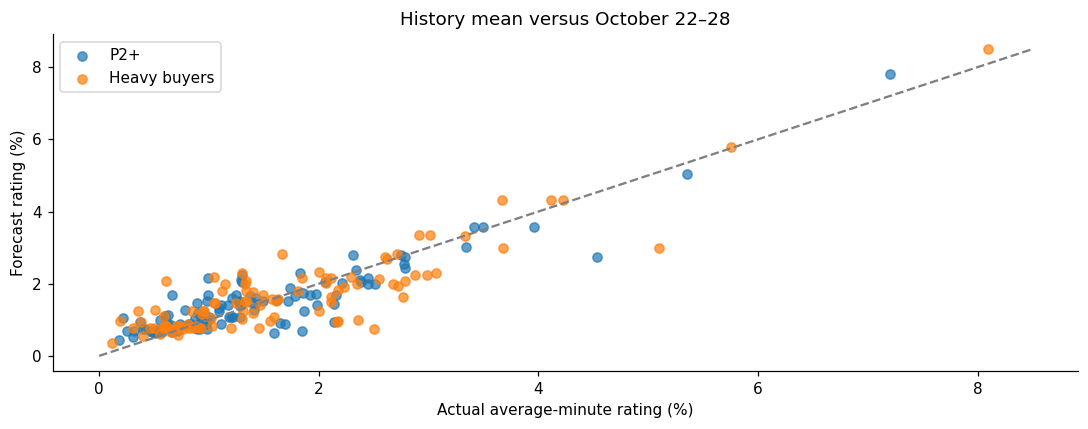

In [22]:
schedule = programs.sort_values(["network_code","start_ts"]).copy()
schedule["Previous program"] = schedule.groupby("network_code").program_name.shift()
schedule["Previous episode"] = schedule.groupby("network_code").episode_name.shift()
miss_tables = {}
for audience in ["P2+","Heavy"]:
    missed = forecasts.nlargest(5,f"{audience} APE").merge(schedule[["telecast_id","episode_name","Previous program","Previous episode","is_live","is_repeat","duration_min"]],on="telecast_id",validate="one_to_one")
    missed["Program"] = missed.program_name+" ("+missed.network_code+")"
    miss_tables[audience] = missed
    print(audience)
    display(missed[["Program","broadcast_date","start_ts","duration_min","is_repeat","episode_name",f"{audience} forecast",f"{audience} rating",f"{audience} APE","Previous program","Previous episode"]].assign(
        **{f"{audience} APE":(missed[f"{audience} APE"]*100).map("{:.1f}".format)}))
fig,ax = plt.subplots()
ax.scatter(forecasts["P2+ rating"],forecasts["P2+ forecast"],label="P2+",alpha=.7)
ax.scatter(forecasts["Heavy rating"],forecasts["Heavy forecast"],label="Heavy buyers",alpha=.7)
limit = forecasts[["P2+ rating","P2+ forecast","Heavy rating","Heavy forecast"]].max().max()
ax.plot([0,limit],[0,limit],color="gray",linestyle="--")
ax.set(xlabel="Actual average-minute rating (%)",ylabel="Forecast rating (%)",title="History mean versus October 22–28")
ax.legend()
fig.tight_layout()
plt.show()

**Answer:** Krapopolis (FOX) on 2024-10-27 is the largest P2+ miss: the history mean is 1.06 but the actual rating is 0.22. Universal Basic Guys on the same night is another large miss, while the Fire Country miss is a 16-minute Sunday repeat after The Equalizer; its history average mixes different episodes, durations and repeat status. Accused (FOX) on 2024-10-22 followed Murder in a Small Town, and What Would You Do? (ABC) on 2024-10-23 followed Abbott Elementary after The Golden Bachelorette. These schedule checks establish different content and lead-ins, but do not prove a causal explanation for each audience change. Heavy buyers have fewer observed panelists, and the same absolute noise becomes a larger percentage error when the actual target rating is small. A better forecast would separate original episodes from repeats and use slot duration, sports overruns, lead-ins and competing events, with shrinkage for thin target samples

## Task 5.1 — The plan

In [23]:
budget = 1_000_000
costs = program_table["Cost per :30"].round().astype(int)
assert np.allclose(costs,program_table["Cost per :30"])
# не більше двох виходів на очікуваний тижневий ефір
capacity = (program_table.Telecasts*7/31).round().clip(lower=1).astype(int)*2
states = {0:(0.0,())}
for name in program_table.index:
    next_states = {}
    for spent,(delivered,choices) in states.items():
        for count in range(int(capacity[name])+1):
            total = spent+count*int(costs[name])
            if total>budget: break
            score = delivered+count*program_table.loc[name,"Target viewers"]
            if total not in next_states or score>next_states[total][0]:
                next_states[total] = (score,choices+(count,))
    states = next_states
plan_cost,(plan_impressions,choices) = max(states.items(),key=lambda x:x[1][0])
plan = program_table.copy()
plan["Spots"] = choices
plan = plan.loc[plan.Spots.gt(0)].copy()
plan["Cost"] = plan.Spots*plan["Cost per :30"]
plan["Target impressions"] = plan.Spots*plan["Target viewers"]
plan["Adult impressions"] = plan.Spots*plan["Adult viewers"]
plan_composition = plan["Target impressions"].sum()/plan["Adult impressions"].sum()
off_target_cost_share = (plan.Cost*(1-plan.Composition)).sum()/plan.Cost.sum()
off_target_cost = plan_cost*off_target_cost_share
assert plan_cost<=budget and np.isclose(plan.Cost.sum(),plan_cost)
assert np.isclose(plan["Target impressions"].sum(),plan_impressions)
assert len(plan)>=2 and (plan.Spots<=capacity.reindex(plan.index)).all()
display(plan[["Spots","Cost","Target impressions"]].assign(Cost=plan.Cost.map("{:.0f}".format),
    **{"Target impressions":plan["Target impressions"].map("{:.0f}".format)}))
print("Plan cost ($):",plan_cost)
print("Plan target impressions (M):",f"{plan_impressions/1e6:.1f}")
print("Unspent budget (USD):",budget-plan_cost)
print("Plan target composition:",f"{plan_composition:.3f}")
print("Spend-weighted off-target share:",f"{off_target_cost_share:.3f}")
print("Composition-proportional off-target cost (USD):",f"{off_target_cost:.0f}")

,Spots,Cost,Target impressions
Program,,,
Dancing with the Stars (ABC),3,475800,4692694
Hannity (FNC),8,319200,3335074
Unsellable Houses (HGTV),6,77400,1903480
Halloween Wars (FOOD),4,38800,647705
Grotesquerie (FX),11,83512,1366591


Plan cost ($): 994712
Plan target impressions (M): 11.9
Unspent budget (USD): 5288
Plan target composition: 0.186
Spend-weighted off-target share: 0.816
Composition-proportional off-target cost (USD): 811844


## Task 5.2 — Recommendation

I would provisionally buy 3 in Dancing with the Stars (ABC), 8 in Hannity (FNC), 6 in Unsellable Houses (HGTV), 4 in Halloween Wars (FOOD), 11 in Grotesquerie (FX), subject to confirming November inventory, especially the seasonal titles. At the Task 2 mean prices the plan costs USD 994,712, leaves USD 5,288 and projects 11.9 million heavy-buyer impressions, including repeat exposures rather than unique reach. The allocation maximizes projected target impressions under the stated planning cap of two spots per estimated weekly airing, combining HGTV's low CPM with extra volume from the other programs. Its target composition is 18.6% of adult impressions, so there is substantial off-target delivery. A spend-weighted composition allocation puts about 81.6% of cost, or USD 811,844, against non-heavy adult viewers; that is a proportional proxy rather than a separately billed amount, and it excludes child viewing from the composition base. The heavy-buyer backtest MAPE is 38.6%, so I would book a target-audience guarantee and agree make-goods for under-delivery without treating MAPE as a confidence interval or a probability. After the week I would compare actual average-minute target impressions, cost and CPM with the plan, check exposure frequency and off-target composition, and reconcile any delivery shortfall with the seller.

## Bonus

In [24]:
KAGGLE_USERNAME = ""
print("Kaggle username:",KAGGLE_USERNAME or "not provided")

def forecast_new_schedule(new_programs):
    metric_columns = ["P2+ rating","Adults rating","Heavy rating","Kestrel rating"]
    history = telecast_metrics
    by_program = history.groupby(["network_code","program_name"])[metric_columns].mean()
    by_network = history.groupby("network_code")[metric_columns].mean()
    rows = new_programs[["telecast_id","network_code","program_name"]].copy()
    rows = rows.join(by_program,on=["network_code","program_name"])
    for column in metric_columns:
        rows[column] = rows[column].fillna(rows.network_code.map(by_network[column])).fillna(history[column].mean()).clip(0,100)
    return rows

print("Competition submission:","not submitted; private files and account access required")
print("Analysis runtime (seconds):",f"{time.perf_counter()-started:.1f}")

Kaggle username: not provided
Competition submission: not submitted; private files and account access required
Analysis runtime (seconds): 28.0


**Answr:** the included function uses October program means, with network and overall fallbacks for unseen titles, as a starting baseline for a future schedule. It is not a competition entry: the private November files, required five-audience submission schema and Kaggle username have not been supplied, so no submission or leaderboard bonus is claimed